# Household types bar chart

Run the cells from top to bottom. Put `All_Residential.txt` in the same folder as this notebook, or change `file_path` below. This follows the original notebook's cleaning: a missing house type is filled with the most common type. Requires `pandas` and `matplotlib`.

In [1]:
from pathlib import Path
from io import StringIO

import pandas as pd
import matplotlib.pyplot as plt

## Settings
Change the file path or chart styling here.

In [2]:
file_path = Path("All_Residential.txt")
output_path = Path("household_types.png")
bar_color = "#477DB3"
chart_title = "Households by house type"
figure_size = (9, 5)

## Load and clean the metadata

In [3]:
text = file_path.read_text(encoding="utf-8")
if "***" not in text:
    raise ValueError("Could not find the *** marker at the end of the table.")

table = text.split("***", 1)[0]
metadata = pd.read_fwf(StringIO(table)).drop(index=0).copy()
if "HouseType" not in metadata.columns:
    raise ValueError("The input table has no HouseType column.")

metadata["HouseType_missing"] = metadata["HouseType"].isna().astype(int)
mode = metadata["HouseType"].mode()
if mode.empty:
    raise ValueError("No house types are available to calculate the mode.")
metadata["HouseType"] = metadata["HouseType"].fillna(mode.iloc[0])

print(f"Total houses: {len(metadata)}")
print(f"Imputed house types: {metadata['HouseType_missing'].sum()}")

Total houses: 28
Imputed house types: 1


## Count and plot house types

,HouseType,Houses
0,apartment,9
6,special,5
2,character,4
5,modern,4
1,bungalow,3
3,duplex,2
4,laneway,1


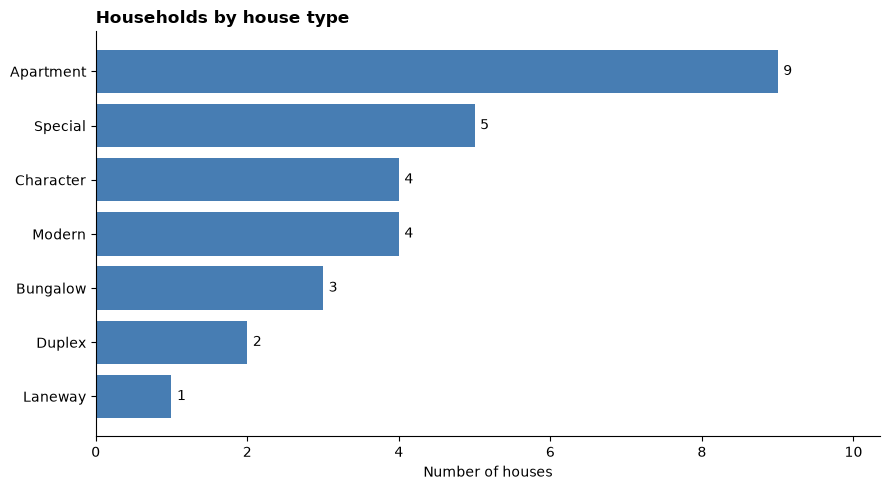

Chart saved to household_types.png


In [4]:
counts = (metadata.groupby("HouseType").size().reset_index(name="Houses")
          .sort_values(["Houses", "HouseType"], ascending=[False, True]))
display(counts)

fig, ax = plt.subplots(figsize=figure_size)
bars = ax.barh(counts["HouseType"].str.title(), counts["Houses"], color=bar_color)
ax.invert_yaxis()
ax.set_title(chart_title, loc="left", weight="bold")
ax.set_xlabel("Number of houses")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.bar_label(bars, padding=4)
ax.set_xlim(0, counts["Houses"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Chart saved to {output_path}")